# Caso 2 — Clustering con Moons (`KMeans`, `DBSCAN`, `SpectralClustering`)
**Curso:** Aprendizaje de Máquina (IX ciclo, grupo B) — UNAP  
**Responsable:** Ccapa Mamani Franklyn Antony

## 1. Librerías y datos

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, SpectralClustering
from sklearn.metrics import silhouette_samples

sys.path.insert(0, str(Path.cwd().parent / "src"))
from clustering_utils import (
    PALETTE_CLUSTERS,
    set_minimalist_style,
    evaluate_clustering,
    compute_elbow_and_internal_curves,
    plot_scatter_minimal,
    plot_metrics_bar_comparison,
)

set_minimalist_style()

X_raw, y = make_moons(n_samples=500, noise=0.08, random_state=42)
X = StandardScaler().fit_transform(X_raw)
print(f"Muestras: {X.shape[0]} | Características: {X.shape[1]}")

Muestras: 500 | Características: 2


## 2. Entrenamiento y métricas

In [2]:
km = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=42)
y_km = km.fit_predict(X)
y_db = DBSCAN(eps=0.30, min_samples=5).fit_predict(X)
y_sc = SpectralClustering(n_clusters=2, affinity="nearest_neighbors", n_neighbors=15, random_state=42).fit_predict(X)

df_moons = pd.DataFrame([
    evaluate_clustering(X, y, y_km, "K-Means (k=2)", "Moons", km.inertia_),
    evaluate_clustering(X, y, y_db, "DBSCAN (eps=0.30)", "Moons"),
    evaluate_clustering(X, y, y_sc, "Spectral (k-NN=15)", "Moons"),
])
display(df_moons)

,Dataset,Modelo,Clusters_Detectados,Puntos_Ruido,Ruido_Pct,ARI,V_Measure,Homogeneidad,Completitud,Silhouette,Davies_Bouldin,Inercia_WCSS
0,Moons,K-Means (k=2),2,0,0.0,0.4451,0.3515,0.3515,0.3515,0.4932,0.8132,419.12
1,Moons,DBSCAN (eps=0.30),2,0,0.0,1.0000,1.0000,1.0000,1.0000,0.3836,1.0241,NaN
2,Moons,Spectral (k-NN=15),2,0,0.0,1.0000,1.0000,1.0000,1.0000,0.3836,1.0241,NaN


## 3. Visualización de fronteras

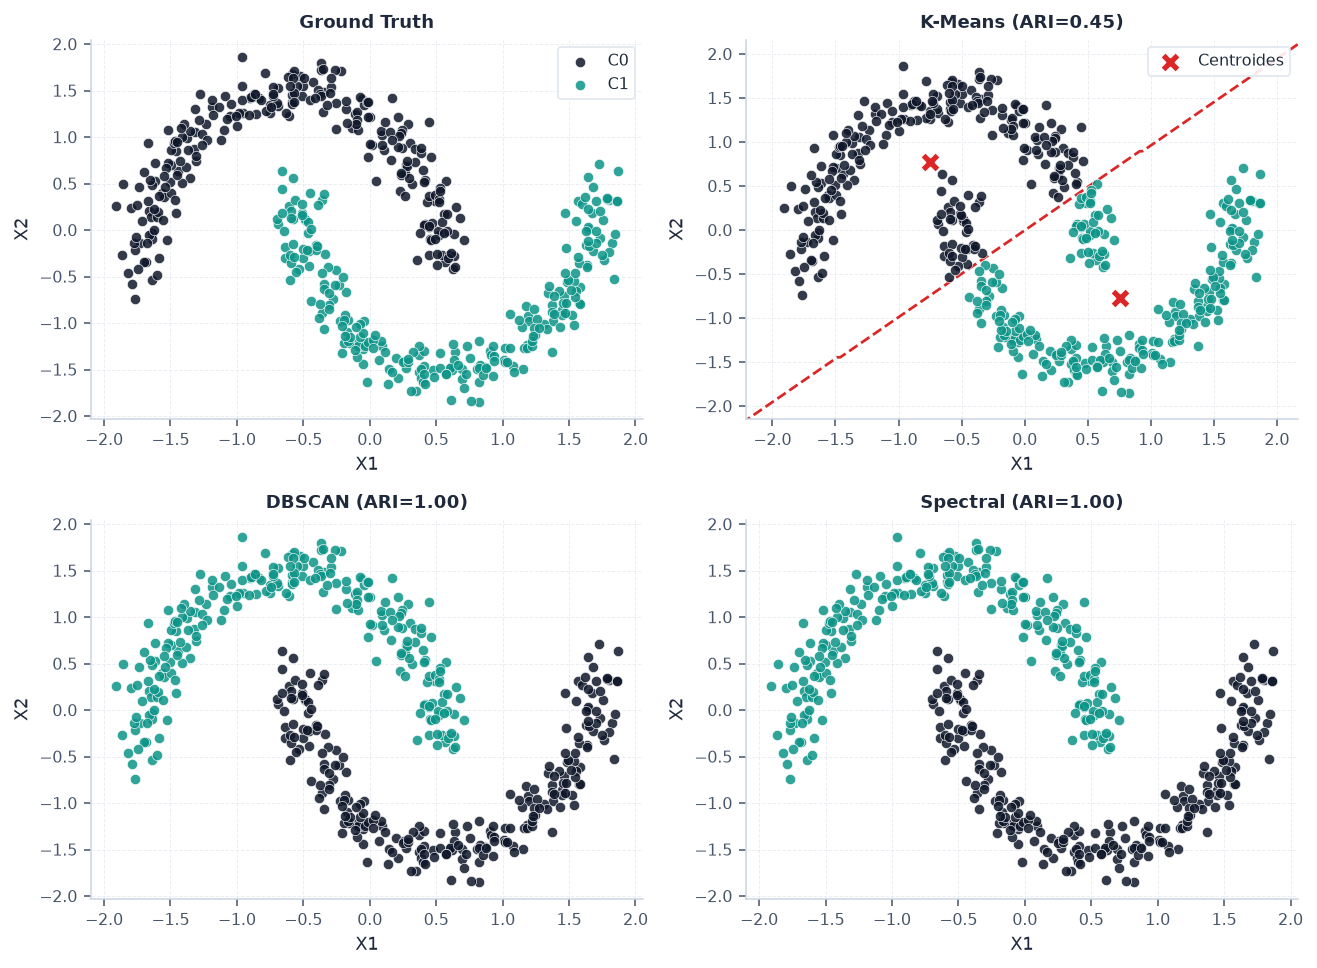

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(9.5, 7.0))
plot_scatter_minimal(axes[0, 0], X, y, "Ground Truth", show_legend=True)

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 200),
    np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 200),
)
Z_km = km.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[0, 1].contour(xx, yy, Z_km, levels=[0.5], colors=["#DC2626"], linewidths=1.4, linestyles="--")

plot_scatter_minimal(axes[0, 1], X, y_km, f"K-Means (ARI={df_moons.loc[0, 'ARI']:.2f})", centroids_2d=km.cluster_centers_)
plot_scatter_minimal(axes[1, 0], X, y_db, f"DBSCAN (ARI={df_moons.loc[1, 'ARI']:.2f})")
plot_scatter_minimal(axes[1, 1], X, y_sc, f"Spectral (ARI={df_moons.loc[2, 'ARI']:.2f})")
fig.tight_layout()
plt.show()

## 4. Método del Codo y perfiles de Silhouette

,k,Inercia_WCSS,Silhouette,Davies_Bouldin
0,1,1000.0000,NaN,NaN
1,2,419.1186,0.4932,0.8132
2,3,306.8549,0.4479,0.8555
3,4,203.4875,0.4399,0.9137
4,5,146.9192,0.4731,0.7325
5,6,115.8036,0.4873,0.6820
6,7,92.5413,0.4922,0.6629
7,8,74.1956,0.4951,0.6270
8,9,59.8149,0.5107,0.5955


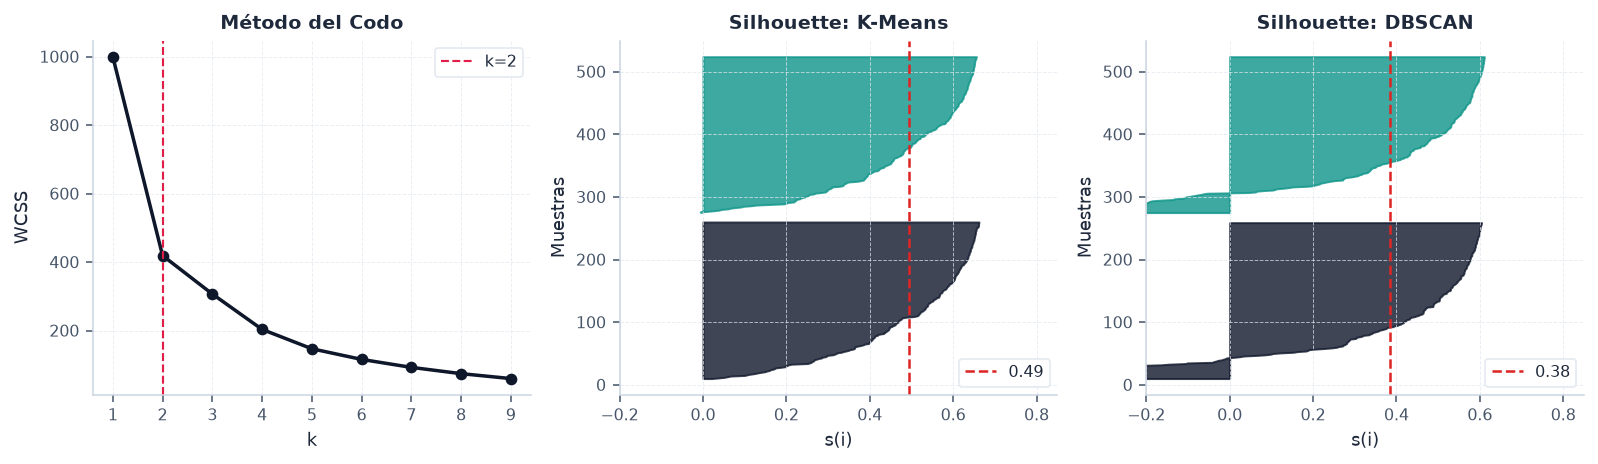

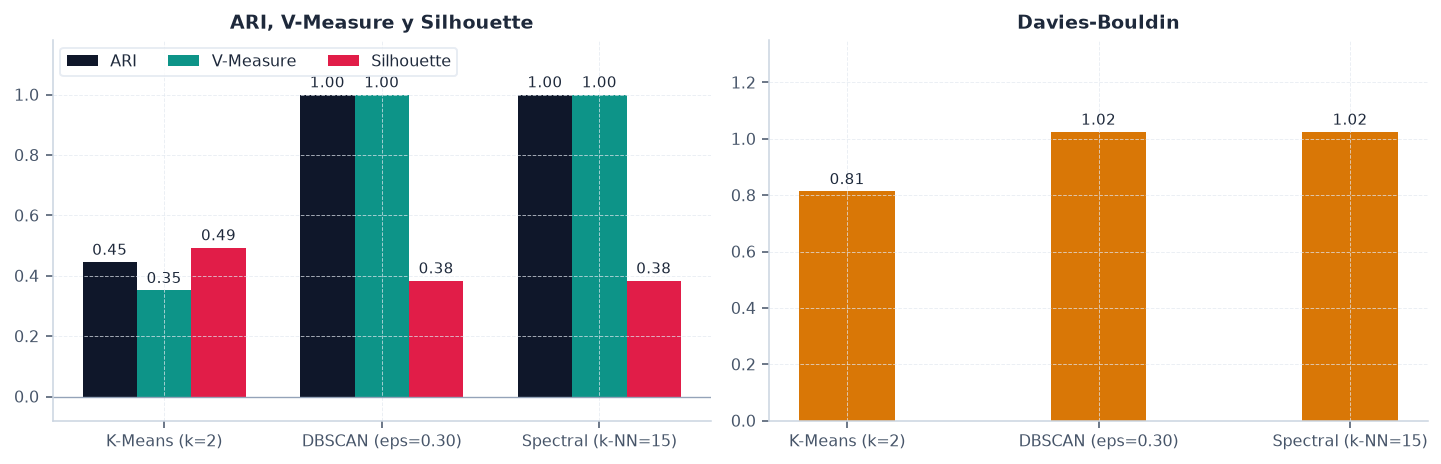

In [4]:
df_curves = compute_elbow_and_internal_curves(X, range(1, 10))
display(df_curves.round(4))

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.4))
axes[0].plot(df_curves["k"], df_curves["Inercia_WCSS"], marker="o", color="#0F172A", lw=1.8, ms=5)
axes[0].axvline(2, color="#E11D48", ls="--", lw=1.1, label="k=2")
axes[0].set_title("Método del Codo")
axes[0].set_xlabel("k")
axes[0].set_ylabel("WCSS")
axes[0].set_xticks(df_curves["k"])
axes[0].legend()

for idx_ax, (s_vals, y_lbls, t_name, sil_v) in enumerate([
    (silhouette_samples(X, y_km), y_km, "Silhouette: K-Means", df_moons.loc[0, "Silhouette"]),
    (silhouette_samples(X, y_db), y_db, "Silhouette: DBSCAN", df_moons.loc[1, "Silhouette"]),
], start=1):
    ax_s = axes[idx_ax]
    y_lower = 10
    for c_i in [0, 1]:
        c_sil = np.sort(s_vals[y_lbls == c_i])
        y_upper = y_lower + c_sil.shape[0]
        ax_s.fill_betweenx(np.arange(y_lower, y_upper), 0, c_sil, color=PALETTE_CLUSTERS[c_i], alpha=0.8)
        y_lower = y_upper + 15
    ax_s.axvline(sil_v, color="#DC2626", ls="--", lw=1.3, label=f"{sil_v:.2f}")
    ax_s.set_title(t_name)
    ax_s.set_xlabel("s(i)")
    ax_s.set_ylabel("Muestras")
    ax_s.set_xlim(-0.2, 0.85)
    ax_s.legend(loc="lower right")

fig.tight_layout()
plt.show()

plot_metrics_bar_comparison(df_moons)
plt.show()